In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense



In [2]:
data = pd.read_csv("creditcard.csv")

In [3]:
data.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [4]:
data.duplicated().sum()

np.int64(1081)

In [5]:
data = data.drop_duplicates()

In [6]:
data["Class"].value_counts()


Class
0    283253
1       473
Name: count, dtype: int64

<Axes: xlabel='Class'>

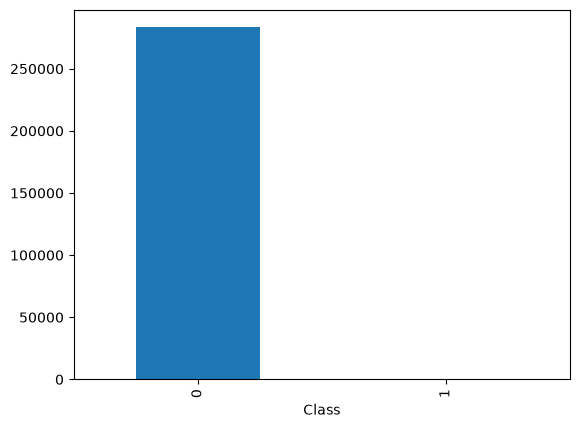

In [7]:
data["Class"].value_counts().plot(
    kind="bar",
)

In [8]:
X = data.drop("Class", axis=1)
y = data["Class"]



In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (226980, 30)
X_test : (56746, 30)


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape :", X_test_scaled.shape)


Training data shape: (226980, 30)
Testing data shape : (56746, 30)


In [11]:
X_train_scaled = X_train_scaled.astype("float32")
X_test_scaled = X_test_scaled.astype("float32")


In [12]:
X_train_normal = X_train_scaled[
    y_train.values == 0
]


In [13]:
input_features = X_train_normal.shape[1]

autoencoder = Sequential([

    # Input layer
    Input(shape=(input_features,)),

    # Encoder
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),

    # Decoder
    Dense(16, activation="relu"),
    Dense(32, activation="relu"),
    Dense(64, activation="relu"),

    # Output layer
    Dense(input_features, activation="linear")
])

autoencoder.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 30)             │         1,950 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,478 (37.02 KB)

 Trainable params: 9,478 (37.02 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

print("Autoencoder compiled successfully.")


Autoencoder compiled successfully.


In [15]:
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,

    epochs=5,

    batch_size=20000,

    validation_split=0.20,

    shuffle=True,

    verbose=1
)


Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.9564 - mae: 0.6593 - val_loss: 0.9737 - val_mae: 0.6574
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.9386 - mae: 0.6553 - val_loss: 0.9485 - val_mae: 0.6541
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.9115 - mae: 0.6524 - val_loss: 0.9148 - val_mae: 0.6507
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.8787 - mae: 0.6485 - val_loss: 0.8790 - val_mae: 0.6474
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.8474 - mae: 0.6441 - val_loss: 0.8461 - val_mae: 0.6385


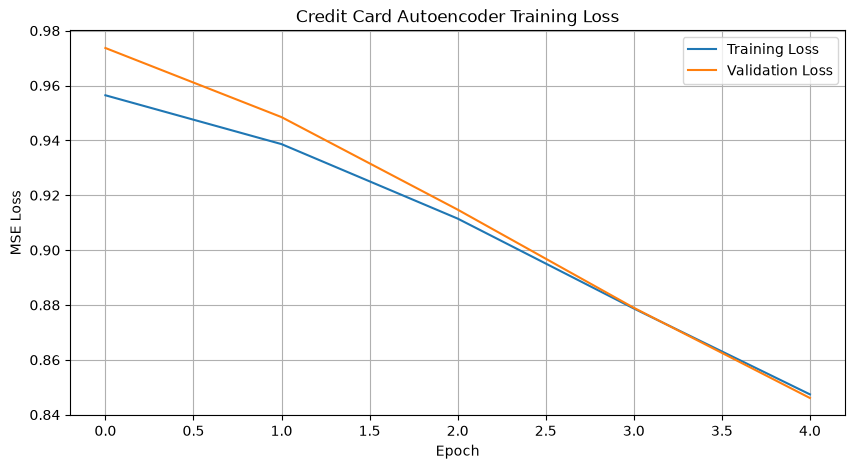

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "Credit Card Autoencoder Training Loss"
)

plt.legend()
plt.grid()

plt.show()


In [17]:
X_train_reconstructed = autoencoder.predict(
    X_train_normal,
    batch_size=256,
    verbose=0
)

print(
    "Original shape:",
    X_train_normal.shape
)

print(
    "Reconstructed shape:",
    X_train_reconstructed.shape
)


Original shape: (226602, 30)
Reconstructed shape: (226602, 30)


In [18]:
normal_error = np.mean(
    np.square(
        X_train_normal -
        X_train_reconstructed
    ),
    axis=1
)

print("Normal reconstruction error:")
print(normal_error[:10])


Normal reconstruction error:
[0.86567837 0.53119963 0.77318734 1.0083106  0.6516942  2.848933
 0.3525381  0.8832282  0.34894717 0.5063074 ]


In [19]:
threshold = np.percentile(
    normal_error,
    95
)

print(
    "Anomaly Threshold:",
    threshold
)


Anomaly Threshold: 1.6490573


In [20]:
X_test_reconstructed = autoencoder.predict(
    X_test_scaled,
    batch_size=256,
    verbose=0
)

print(
    "Test reconstructed shape:",
    X_test_reconstructed.shape
)


Test reconstructed shape: (56746, 30)


In [21]:
test_error = np.mean(
    np.square(
        X_test_scaled -
        X_test_reconstructed
    ),
    axis=1
)

print("First 10 test errors:")
print(test_error[:10])


First 10 test errors:
[0.29553646 0.4300928  0.8732469  0.435429   0.48160866 0.28596652
 0.51094025 0.7977157  1.0399152  0.5628038 ]


In [22]:
y_pred = (
    test_error > threshold
).astype(int)

print("Predicted classes:")
print(y_pred[:20])


Predicted classes:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [23]:
results = pd.DataFrame({
    "Actual_Class": y_test.values,
    "Reconstruction_Error": test_error,
    "Predicted_Class": y_pred
})

results.head(20)


,Actual_Class,Reconstruction_Error,Predicted_Class
0,0,0.295536,0
1,0,0.430093,0
2,0,0.873247,0
3,0,0.435429,0
4,0,0.481609,0
5,0,0.285967,0
6,0,0.510940,0
7,0,0.797716,0
8,0,1.039915,0
9,0,0.562804,0


In [24]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)


Accuracy: 0.949582349416699


In [25]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)


[[53807  2844]
 [   17    78]]


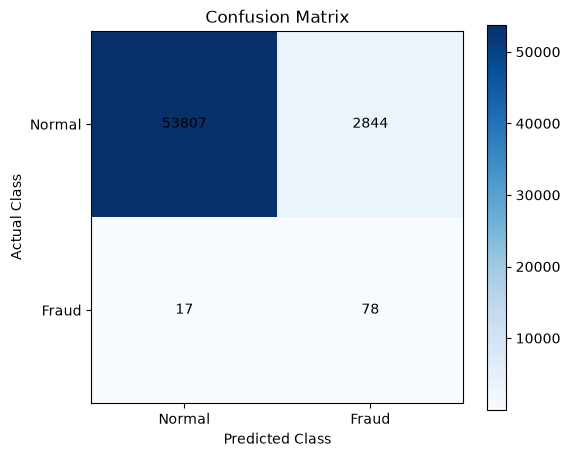

In [26]:
plt.figure(figsize=(6, 5))

plt.imshow(
    cm,
    cmap="Blues"
)

plt.colorbar()

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("Confusion Matrix")

plt.xticks(
    [0, 1],
    ["Normal", "Fraud"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Fraud"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()


In [27]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Normal",
            "Fraud"
        ]
    )
)


              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97     56651
       Fraud       0.03      0.82      0.05        95

    accuracy                           0.95     56746
   macro avg       0.51      0.89      0.51     56746
weighted avg       1.00      0.95      0.97     56746



In [28]:
fraud_transactions = results[
    results["Predicted_Class"] == 1
]

print(
    "Number of detected anomalies:",
    len(fraud_transactions)
)

fraud_transactions.head(20)


Number of detected anomalies: 2922


,Actual_Class,Reconstruction_Error,Predicted_Class
34,0,1.890797,1
56,0,2.838653,1
145,0,2.201793,1
154,0,2.060385,1
171,0,1.807854,1
192,0,3.714093,1
198,0,61.190128,1
291,0,2.093942,1
324,0,3.701478,1
375,0,1.884348,1
